
EXPERIMENT NO. 2 A (Group A) 
 
Aim: Predict the price of the Uber ride from a given pickup point to the agreed drop-off location. Perform 
following 
tasks: 1. Pre-process the dataset. 2. Identify outliers. 3. Check the correlation. 4. Implement linear 
regression and ridge, Lasso regression models. 5. Evaluate the models and compare their respective scores 
like R2, RMSE, etc. Dataset link: https://www.kaggle.com/datasets/yasserh/uber-fares-dataset


Name:Aditya Rade
Roll.No:BEAD23167

Outputs:

step-1-Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error

step-2-Load Dataset

In [ ]:
df = pd.read_csv("uber.csv")

print(df.head())
print("\nShape:")
print(df.shape)

print("\nColumns:")
print(df.columns)

print("Name:Aditya Rade Roll No:BEAD23167")

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

step-3-Clean Dataset

In [3]:
print(df.isnull().sum())

df = df.dropna()

print("\nAfter removing missing values:")
print(df.shape)

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

After removing missing values:
(199999, 9)


step-4-Convert date

In [4]:
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"],
    errors="coerce"
)

df = df.dropna(subset=["pickup_datetime"])

step-5-Create useful features

In [25]:

# Convert pickup_datetime into datetime format
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"],
    errors="coerce"
)

# Check the conversion
print(df["pickup_datetime"].dtype)

# Create date/time features
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year

print(df.head())

print("Name:Aditya Rade Roll No:BEAD23167")



datetime64[ns, UTC]
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

            pickup_datetime  pickup_longitude  pickup_latitude  \
0 2015-05-07 19:52:06+00:00        -73.999817        40.738354   
1 2009-07-17 20:04:56+00:00        -73.994355        40.728225   
2 2009-08-24 21:45:00+00:00        -74.005043        40.740770   
3 2009-06-26 08:22:21+00:00        -73.976124        40.790844   
4 2014-08-28 17:47:00+00:00        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  hour  day  month  \
0         -73.999512         40.723217                1    19    7      5   
1         -73.994710         40.750325                1    20 

step-6-Remove invalid values

In [6]:
df = df[
    (df["fare_amount"] > 0) &
    (df["passenger_count"] > 0)
]

print("Cleaned shape:", df.shape)

Cleaned shape: (199269, 12)


step-7-Check outliers

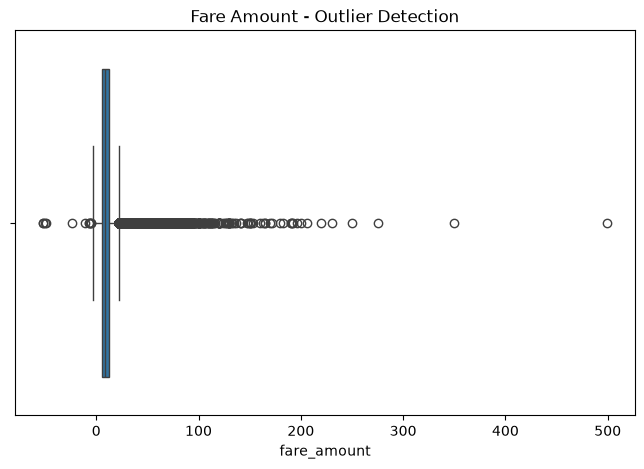

Name:Aditya Rade Roll No:BEAD23167


In [26]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df["fare_amount"])

plt.title("Fare Amount - Outlier Detection")
plt.show()
print("Name:Aditya Rade Roll No:BEAD23167")

step-8-Remove extreme fare values

In [8]:
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[
    (df["fare_amount"] >= lower) &
    (df["fare_amount"] <= upper)
]

print("Shape after outlier removal:", df.shape)

Shape after outlier removal: (182148, 12)


step-9-Correlation

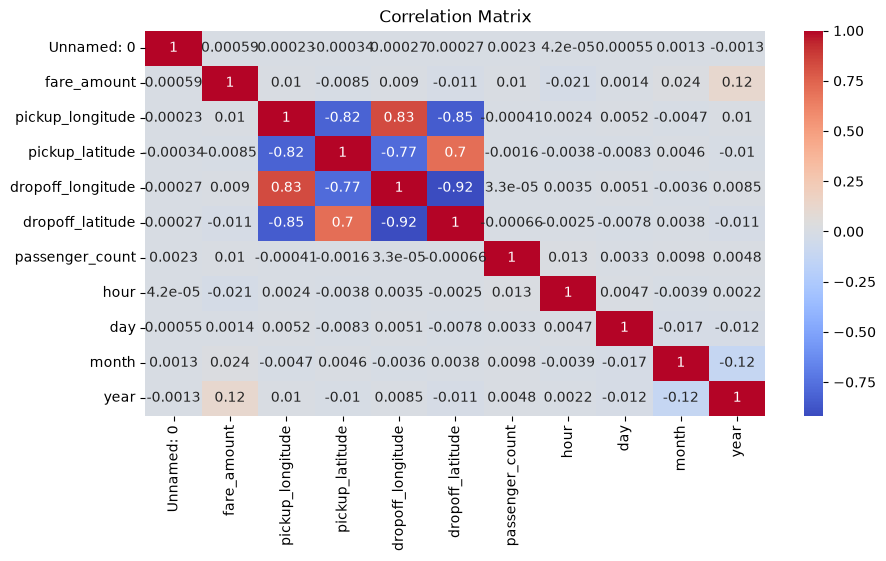

Name:Aditya Rade Roll No:BEAD23167


In [ ]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()
print("Name:Aditya Rade Roll No:BEAD23167")

step-10-Prepare X and y

In [10]:
features = [
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "passenger_count",
    "hour",
    "day",
    "month",
    "year"
]

X = df[features]
y = df["fare_amount"]

step-11-Train-test split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (145718, 9)
Testing data: (36430, 9)


step-12-Linear Regression

In [12]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

linear_r2 = r2_score(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))

print("Linear Regression")
print("R2 Score:", linear_r2)
print("RMSE:", linear_rmse)

Linear Regression
R2 Score: 0.021851684878975597
RMSE: 4.084138406300627


step-13-Ridge Regression

In [13]:
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train, y_train)

ridge_pred = ridge_model.predict(X_test)

ridge_r2 = r2_score(y_test, ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))

print("Ridge Regression")
print("R2 Score:", ridge_r2)
print("RMSE:", ridge_rmse)

Ridge Regression
R2 Score: 0.021851682609159595
RMSE: 4.084138411039296


step-14-Lasso Regression

In [14]:
lasso_model = Lasso(alpha=0.001)

lasso_model.fit(X_train, y_train)

lasso_pred = lasso_model.predict(X_test)

lasso_r2 = r2_score(y_test, lasso_pred)
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_pred))

print("Lasso Regression")
print("R2 Score:", lasso_r2)
print("RMSE:", lasso_rmse)

Lasso Regression
R2 Score: 0.021849391100470017
RMSE: 4.084143194993329


step-15-Compare models

In [18]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],
    "R2 Score": [
        linear_r2,
        ridge_r2,
        lasso_r2
    ],
    "RMSE": [
        linear_rmse,
        ridge_rmse,
        lasso_rmse
    ]
})

print(results)




print("Name:Aditya Rade Roll No:BEAD23167")

               Model  R2 Score      RMSE
0  Linear Regression  0.021852  4.084138
1   Ridge Regression  0.021852  4.084138
2   Lasso Regression  0.021849  4.084143
Name:Aditya Rade Roll No:BEAD23167
